# Stage 05 · Autoencoders, Latent Spaces (`vkvis`), & Modern Mini-Llama (`vktorch`)

Powered by **`vktorch`'s fused single-pass Vulkan SPIR-V kernels** (`AdamW`, `SGD`, `GELU`), this notebook explores two flagship modern deep learning architectures on your own GPU:
1. **Deep Autoencoder + `vkvis` UMAP Latent Space:** Compress 32D noisy data through an 8D bottleneck and visualize how the neural network untangles clusters into a clean latent manifold.
2. **Modern Mini-Llama (`RMSNorm` + `SwiGLU` + Causal Attention):** Train a Llama-architecture character-level LLM from scratch on Vulkan GPU and generate text autoregressively!

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Denoising Autoencoder (4,168 params) trained 25 epochs in 14.77s | MSE: 1.903 -> 0.195


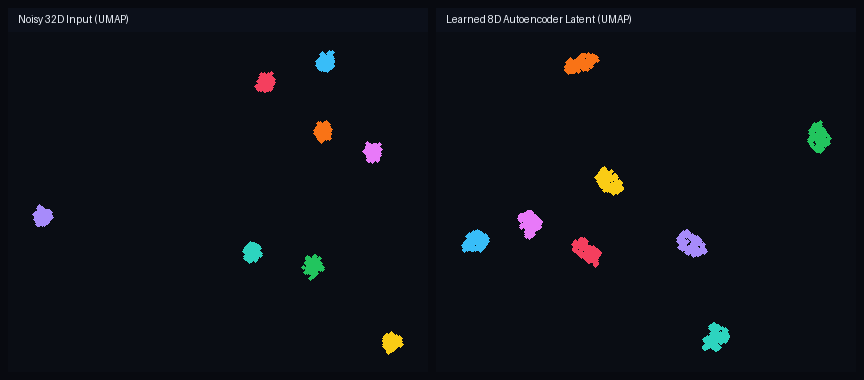

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vktorch as vt
from vktorch import F, nn, optim
from vktorch.data import DataLoader, TensorDataset
import vkvis as vv

# 1. Create an 8-class 32D dataset corrupted by heavy Gaussian noise
rng = np.random.default_rng(42)
n_cls, per_c, D = 8, 220, 32
centers = rng.standard_normal((n_cls, D)).astype(np.float32) * 2.4
X_clean = np.vstack([centers[c] + rng.standard_normal((per_c, D)).astype(np.float32) * 0.45 for c in range(n_cls)])
X_noisy = (X_clean + rng.normal(0.0, 0.85, X_clean.shape)).astype(np.float32)
y_cls = np.repeat(np.arange(n_cls, dtype=np.int32), per_c)

class DenoisingAutoencoder(nn.Module):
    def __init__(self, d_in=32, d_latent=8):
        super().__init__()
        self.enc1 = nn.Linear(d_in, 48, seed=1)
        self.ln1 = nn.LayerNorm(48)
        self.enc2 = nn.Linear(48, d_latent, seed=2)
        self.dec1 = nn.Linear(d_latent, 48, seed=3)
        self.ln2 = nn.LayerNorm(48)
        self.dec2 = nn.Linear(48, d_in, seed=4)

    def encode(self, x):
        return self.enc2(self.ln1(self.enc1(x).gelu()))

    def forward(self, x):
        z = self.encode(x)
        return self.dec2(self.ln2(self.dec1(z).gelu()))

ae = DenoisingAutoencoder(d_in=D, d_latent=8)
opt = optim.AdamW(ae.parameters(), lr=2e-2, weight_decay=1e-3)
sched = optim.CosineAnnealingLR(opt, T_max=25)
loader = DataLoader(TensorDataset(X_noisy, X_clean), batch_size=128, shuffle=True, seed=42)

t0 = time.perf_counter()
losses = []
for ep in range(25):
    ep_l = 0.0
    for xb, yb in loader:
        opt.zero_grad()
        loss = F.mse_loss(ae(xb), yb)
        loss.backward()
        opt.step()
        ep_l += loss.item()
    sched.step()
    losses.append(ep_l / len(loader))
dt = time.perf_counter() - t0
print(f"Denoising Autoencoder ({ae.num_parameters():,} params) trained 25 epochs in {dt:.2f}s | MSE: {losses[0]:.3f} -> {losses[-1]:.3f}")

# Extract 8D learned latent vectors and compare Raw 32D vs Latent 8D via GPU UMAP
with vt.no_grad():
    Z = ae.encode(vt.Tensor(X_noisy)).numpy()

Y_raw = vv.UMAP(n_neighbors=15, n_epochs=100, seed=42).fit_transform(X_noisy)
Y_lat = vv.UMAP(n_neighbors=15, n_epochs=100, seed=42).fit_transform(Z)
vv.compare_embeddings(
    {"Noisy 32D Input (UMAP)": Y_raw, "Learned 8D Autoencoder Latent (UMAP)": Y_lat},
    labels=y_cls, width=420, height=340, ncols=2, point_size=2,
)

## 2. Modern Mini-Llama (`RMSNorm` + `SwiGLU` + Causal Self-Attention)

Unlike GPT-2 (`LayerNorm` + `GELU`), modern LLMs (Llama 3, Gemma, Mistral) use **`RMSNorm`** and **`SwiGLU`** gated feed-forward layers. Let's train a `MiniLlama` with `vktorch.nn.LlamaBlock` + fused SPIR-V `AdamW` and watch it generate text!

In [2]:
text = (
    "vulkan gpu compute lets anyone learn how ai works on the hardware they already own. "
    "vktorch trains neural networks with fused spirv kernels and zero cuda required. "
    "modern transformers use rmsnorm swiglu and causal self attention on gpu. "
) * 5

vocab = sorted(set(text))
stoi = {c: i for i, c in enumerate(vocab)}
itos = {i: c for c, i in stoi.items()}
V = len(vocab)
T_ctx = 28
ids = np.array([stoi[c] for c in text], dtype=np.int32)

class MiniLlama(nn.Module):
    def __init__(self, vocab_size, d_model=48, n_heads=4, max_len=T_ctx):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, d_model, seed=1)
        self.pos = nn.Embedding(max_len, d_model, seed=2)
        self.block = nn.LlamaBlock(d_model, n_heads, hidden_dim=96, is_causal=True, seed=3)
        self.norm = nn.RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False, seed=4)

    def forward(self, idx):
        B, T = idx.shape
        p = np.broadcast_to(np.arange(T, dtype=np.int32)[None, :], (B, T))
        h = self.tok(idx) + self.pos(p)
        return self.lm_head(self.norm(self.block(h)))

llama = MiniLlama(V)
opt_l = optim.AdamW(llama.parameters(), lr=2.5e-2, weight_decay=1e-3)
sched_l = optim.CosineAnnealingLR(opt_l, T_max=150, eta_min=2e-3)
rng_l = np.random.default_rng(7)

t0 = time.perf_counter()
for step in range(150):
    starts = rng_l.integers(0, len(ids) - T_ctx - 1, size=24)
    xb = np.stack([ids[s : s + T_ctx] for s in starts])
    yb = np.stack([ids[s + 1 : s + T_ctx + 1] for s in starts])
    opt_l.zero_grad()
    loss = F.cross_entropy(llama(xb), yb)
    loss.backward()
    optim.clip_grad_norm_(llama.parameters(), 1.5)
    opt_l.step()
    sched_l.step()
    if step in (0, 50, 100, 149):
        print(f"step {step:3d} | loss = {loss.item():.3f} | lr = {opt_l.lr:.4f}")

print(f"MiniLlama ({llama.num_parameters():,} params) trained 150 steps in {time.perf_counter()-t0:.2f}s")

for prompt in ("vulkan gpu ", "vktorch trains ", "modern transformers "):
    ctx = [stoi[c] for c in prompt]
    with vt.no_grad():
        for _ in range(58):
            logits = llama(np.array([ctx[-T_ctx:]], dtype=np.int32)).numpy()[0, -1]
            ctx.append(int(np.argmax(logits)))
    print(f"  [{prompt!r}] -> {''.join(itos[i] for i in ctx)}")

[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


step   0 | loss = 3.311 | lr = 0.0250


step  50 | loss = 0.974 | lr = 0.0190


step 100 | loss = 0.349 | lr = 0.0075


step 149 | loss = 0.264 | lr = 0.0020
MiniLlama (27,120 params) trained 150 steps in 13.00s


  ['vulkan gpu '] -> vulkan gpu compute lets anyone learn how ai works on the hardware the


  ['vktorch trains '] -> vktorch trains neural networks with fused spirv kernels and zero cuda req


  ['modern transformers '] -> modern transformers use rmsnorm swiglu and causal self attentiontin gpu. vulka
